In [1]:
import sys
from pathlib import Path
import importlib

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir() and (candidate / "project.ipynb").is_file():
        ROOT = candidate
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pyspark.sql import SparkSession
from src.dataOI import DataOI

SEED = 42
# True: rebuild the encoded split from the raw CSV; False: load its local cache.
# The flag controls input preparation, not model training.
REBUILD = True

# `spark.driver.memory` is read only when the JVM starts. Restart the kernel after changing it.
spark = SparkSession.builder \
                            .master("local[*]")\
                            .appName("DrugReviewClassification")\
                            .config("spark.driver.memory","6g")\
                            .getOrCreate()
spark_context = spark.sparkContext
spark_context.setLogLevel("ERROR")
data_oi = DataOI()


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/02 00:47:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df_raw = data_oi.load_raw_data()
df_raw.show(truncate= 80)
print("rows:", df_raw.count())

+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|               Birth Cont

### Exploratory Data Analysis (EDA)
Begin by trying to comprehend what your dataset conveys.
- What type of data are you currently exploring?
- What is the granularity of the data?
- What does the distribution of the data look like? Are there any outliers? Are there any missing or invalid entries?
- Is there any correlation between the variables you are interested in exploring?
- How would you cleanly and accurately visualize the relationship among variables?

In [3]:
from src.eda import EDA

eda_raw = EDA(df_raw)
eda_raw.dataframe_overview()

DataFrame overview
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|               Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|              Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                  Lybrel|               Birth Control|"I used to take another oral contrace

In [4]:
eda_raw.granularity()

DataFrame granularity
Total row count: 161297
`drugName`:
+-------------------------------+
|                       drugName|
+-------------------------------+
|                         Dulera|
|                         Prozac|
|                          Arava|
|                         Maxalt|
|                     Tazarotene|
|                      Primidone|
|Acetaminophen / diphenhydramine|
|                       Treximet|
|                         Avapro|
|                        Prograf|
|                      Auranofin|
|               Spiriva Respimat|
|              Parafon Forte DSC|
|                       Dupixent|
|                      Nebivolol|
|                         Nexium|
|                         Ceftin|
|                        Enjuvia|
|                    Benicar HCT|
|                    Penciclovir|
+-------------------------------+
only showing top 20 rows
`drugName` count: 3436
`condition`:
+-------------------------------------------+
|                  

Data Distribution
`rating` is in the range [1, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|21619|
|     2| 6931|
|     3| 6513|
|     4| 5012|
|     5| 8013|
|     6| 6343|
|     7| 9456|
|     8|18890|
|     9|27531|
|    10|50989|
+------+-----+

+------------------+-----------------+-------------------+
|          variance|           stddev|           skewness|
+------------------+-----------------+-------------------+
|10.708138452208162|3.272329209020413|-0.7986194576447084|
+------------------+-----------------+-------------------+

`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

The highest `usefulCount` record:
+--------+----------+----------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|  drugName| condi

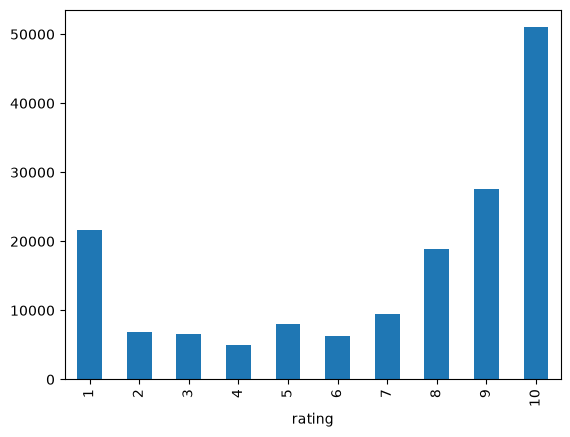

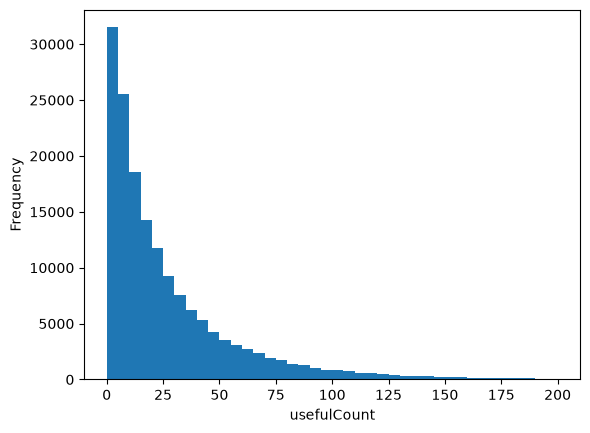

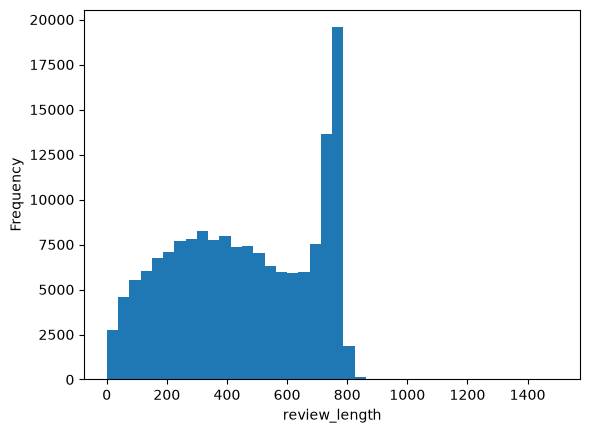

In [5]:
eda_raw.distribution_inspect()

In [6]:
eda_raw.correlation()

Data Field Correlation
+------------------+--------------------+-------------------+
|rating_usefulCount|         rating_date|   usefulCount_date|
+------------------+--------------------+-------------------+
|0.2341853750636649|-0.19623579544730904|-0.2690699925232411|
+------------------+--------------------+-------------------+



### Data Cleaning
A crucial step in the data preprocessing pipeline, aimed at improving the quality and accuracy of the dataset before analysis.
- Identifying Missing Values
- Handling Outliers
- Correcting Invalid Entries
- Removing Duplicates
- Standardizing Data: Ensure consistency in data representation.
- Transforming Variables: Apply necessary transformations to variables to enhance their interpretability or suitability for analysis.

Before data cleaning:
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|   

After replacement: 0 `condition` values still match configured repairs, 0 `review` values contain HTML entities


After keeping the row with the highest `usefulCount` for each `review`
Row count: 159498 -> 111169, removed 48329 rows
Added `usefulCount_log` = log(1 + `usefulCount`)


+---------------+------------------+------------------+-------------------+
|         column|          variance|            stddev|           skewness|
+---------------+------------------+------------------+-------------------+
|    usefulCount|1281.0596694332753| 35.79189390676715|  4.488069648978944|
|usefulCount_log|1.4185196157482696|1.1910162113708904|-0.2966446191417038|
+---------------+------------------+------------------+-------------------+

Added `days` = days since 1970-01-01 from `date`
Set `rating_p1` = `rating` - 1


After data cleaning:
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|uniqueID|                                              drugName|          condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log| days|rating_p1|
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|   75849|                                             Temazepam|           Insomnia|                                     15mg ineffective. 30mg worked pretty well. |     5|2013-05-21|         31|3.4657359027997265|15846|        4|
|  128876|                                         

+---------------------------------+
|                         drugName|
+---------------------------------+
|                           Maxalt|
|                           Avapro|
|  Acetaminophen / diphenhydramine|
|                           Prozac|
|                         Treximet|
|                        Nebivolol|
|                           Nexium|
|                       Gabapentin|
|                          Privine|
|                 Dextromethorphan|
|                        Adapalene|
|                      Dulaglutide|
|                   Levocetirizine|
|                           Zoloft|
|Ethinyl estradiol / norethindrone|
|                           Copper|
|                       Vilazodone|
|                        Tadalafil|
|                Divalproex sodium|
|                           Avelox|
+---------------------------------+
only showing top 20 rows
`drugName` count: 

2963
`condition`:


+-------------------------------------------+
|                                  condition|
+-------------------------------------------+
|    High Cholesterol, Familial Heterozygous|
|    Organ Transplant, Rejection Prophylaxis|
|                          Cluster Headaches|
|                             Panic Disorder|
|                  Abnormal Uterine Bleeding|
|                       Rheumatoid Arthritis|
|                                   Headache|
|                                     Angina|
|                                Prostatitis|
|            Premenstrual Dysphoric Disorder|
|                              HIV Infection|
|              Skin or Soft Tissue Infection|
|                                 Anesthesia|
|         Nausea/Vomiting, Radiation Induced|
|                          Opiate Withdrawal|
|                                   Anorexia|
|                                   Seizures|
|                      Human Papilloma Virus|
|                         Anxiety 

805


`uniqueID` is unique


`review` values are unique
Data Distribution
`rating` is in the range [1, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|14955|
|     2| 4742|
|     3| 4424|
|     4| 3412|
|     5| 5514|
|     6| 4351|
|     7| 6550|
|     8|13074|
|     9|18939|
|    10|35208|
+------+-----+

+------------------+------------------+------------------+
|          variance|            stddev|          skewness|
+------------------+------------------+------------------+
|10.709293362465148|3.2725056703488153|-0.802342877246741|
+------------------+------------------+------------------+

`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

The highest `usefulCount` record:
+--------+--------+----------+--------------------------------------------------------------------------------+------+----------+-----------+---

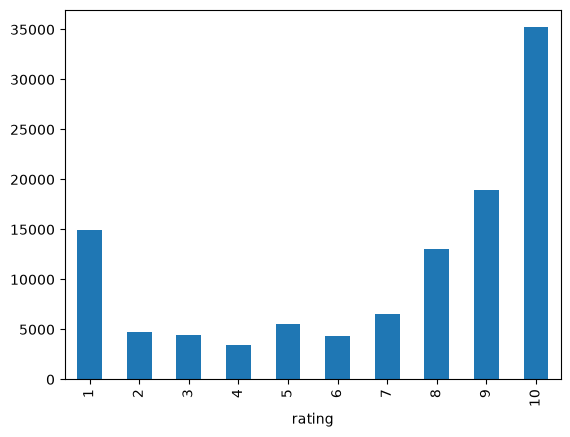

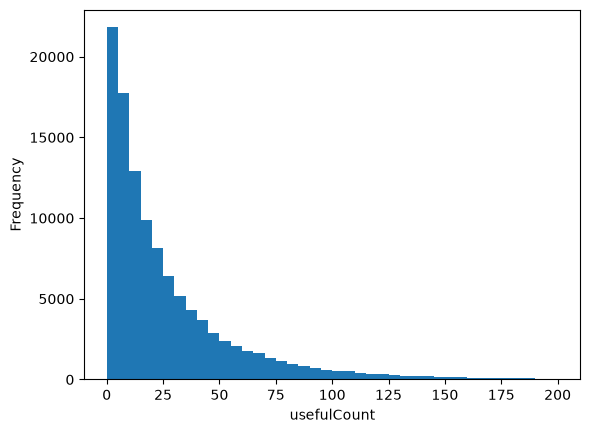

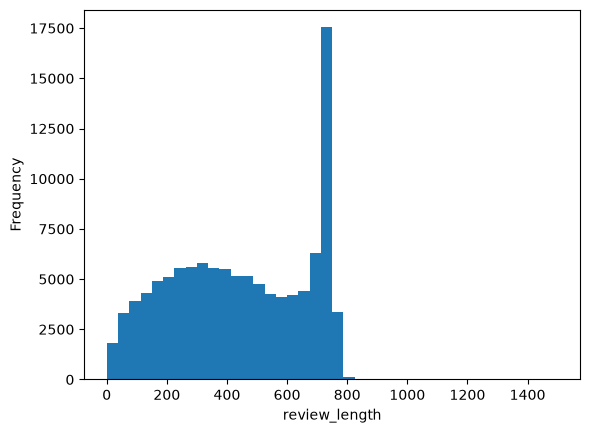

In [7]:
from src.cleaning import data_cleaning

if REBUILD:
    print("Before data cleaning:")
    df_raw.show(10,truncate=80)
    df_cleaned = data_cleaning(df_raw)
    df_cleaned.cache().count()
    print("After data cleaning:")
    df_cleaned.show(10,truncate=80)
    print("Cleaned data overview:")
    eda_cleaned = EDA(df_cleaned)
    eda_cleaned.dataframe_overview()
    eda_cleaned.granularity()
    eda_cleaned.distribution_inspect()


In [ ]:
import src.text_features
importlib.reload(src.text_features)
from src.text_features import text_feature_engineering, baseline_text_feature_engineering

df_baseline_engineered = baseline_text_feature_engineering(df_cleaned)
df_baseline_engineered.cache().count()

if REBUILD:
    print("Before text feature engineering:")
    df_cleaned.show(10,truncate = 80)
    df_engineered = text_feature_engineering(df_cleaned)
    df_engineered.cache().count()
    print("After text feature engineering:")
    df_engineered.show(10,truncate = 80)


Before text feature engineering:
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|uniqueID|                                              drugName|          condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log| days|rating_p1|
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|   75849|                                             Temazepam|           Insomnia|                                     15mg ineffective. 30mg worked pretty well. |     5|2013-05-21|         31|3.4657359027997265|15846|        4|
|  128876|                             

Before character repair: 1117 `review` values require character or whitespace normalization


After character repair: 0 `review` values would change on a second pass (idempotence check)


Contraction repair and expansion: 63216 `review` values changed


{"ts": "2026-11-02 00:49:31.027", "level": "ERROR", "logger": "DataFrameQueryContextLogger", "msg": "[UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `words_featured` cannot be resolved. Did you mean one of the following? [`words_nostop`, `words_stem`, `date`, `words`, `drugName`]. SQLSTATE: 42703", "context": {"file": "java.base/jdk.internal.reflect.DirectMethodHandleAccessor.invoke(DirectMethodHandleAccessor.java", "line": "103)", "fragment": "col", "errorClass": "UNRESOLVED_COLUMN.WITH_SUGGESTION"}, "exception": {"class": "Py4JJavaError", "msg": "An error occurred while calling o1504.select.\n: org.apache.spark.sql.AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `words_featured` cannot be resolved. Did you mean one of the following? [`words_nostop`, `words_stem`, `date`, `words`, `drugName`]. SQLSTATE: 42703;\n'Project [uniqueID#0, drugName#1, condition#1624, 'words_featured, days#4132,

AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `words_featured` cannot be resolved. Did you mean one of the following? [`words_nostop`, `words_stem`, `date`, `words`, `drugName`]. SQLSTATE: 42703;
'Project [uniqueID#0, drugName#1, condition#1624, 'words_featured, days#4132, usefulCount_log#1738, rating#4, rating_p1#4133, review#17958, words#17963]
+- Project [uniqueID#0, drugName#1, condition#1624, review#17958, rating#4, date#5, usefulCount#6, usefulCount_log#1738, days#4132, rating_p1#4133, review_clean#17959, words#17963, words_nostop#17970, stem_words(words_nostop#17970)#17974 AS words_stem#17975]
   +- Project [uniqueID#0, drugName#1, condition#1624, review#17958, rating#4, date#5, usefulCount#6, usefulCount_log#1738, days#4132, rating_p1#4133, review_clean#17959, words#17963, UDF(words#17963) AS words_nostop#17970]
      +- Project [uniqueID#0, drugName#1, condition#1624, review#17958, rating#4, date#5, usefulCount#6, us

In [ ]:
from src.encoder import encoder
from src.split import split_and_weight

df_baseline_train, df_baseline_test = split_and_weight(df_baseline_engineered,SEED)
df_baseline_train,df_baseline_test = encoder(df_baseline_train,df_baseline_test)

if REBUILD:
    df_train, df_test = split_and_weight(df_engineered, SEED)
    df_train, df_test = encoder(df_train, df_test)
    data_oi.save_split_data(df_train,df_test)
else:
    df_train, df_test = data_oi.load_split_data()

In [ ]:
from src.embeddings import EmbeddingModel
# Embedding Baseline Model (TFIDF without text feature engineering)

embedding_baseline_model = EmbeddingModel(df_baseline_train,df_baseline_test)
baseline_name = "baseline"
print("Embedding Baseline Model `baseline` Training")
embedding_baseline_model.tfidf_train(baseline_name)
print("Embedding Baseline Model `baseline` Running")
train_embedding_baseline, test_embedding_baseline = embedding_baseline_model.tfidf_predict(baseline_name)

Embedding Baseline Model `baseline` Training


Embedding Baseline Model `baseline` Running


In [ ]:
from src.embeddings import EmbeddingModel

# Fit registered embeddings before prediction; downstream models read `embedding`.
embedding_model = EmbeddingModel(df_train,df_test)

for name, train_function in EmbeddingModel.train_registry.items():
    print(f"Embedding Model `{name}` Training")
    train_function(embedding_model)

Embedding Model `tfidf` Training


In [ ]:
train_embedding_dict = {}
test_embedding_dict = {}

for name, predict_function in EmbeddingModel.predict_registry.items():
    print(f"Embedding Model `{name}` Running")
    train_embedding_dict[name], test_embedding_dict[name] = predict_function(embedding_model)
    data_oi.save_embedding_data(name,train_embedding_dict[name],test_embedding_dict[name])

Embedding Model `tfidf` Running


In [ ]:
# Analytics Baseline Model (Logistic Regression Model without weight col)

from src.analytics import AnalyticsModel
analytics_baseline_model = AnalyticsModel(train_embedding_baseline,test_embedding_baseline)

print("Analytics Baseline Model `lr` Training")
analytics_baseline_model.lr_train(baseline_name)
print("Analytics Baseline Model `lr` Running")
train_analytics_baseline, test_analytics_baseline = analytics_baseline_model.lr_predict(baseline_name)

Analytics Baseline Model `lr` Training


Analytics Baseline Model `lr` Running


In [ ]:
from src.analytics import AnalyticsModel

train_embedding_dict, test_embedding_dict = data_oi.load_embedding_data()

analytics_models = {}
for embedding_name in train_embedding_dict.keys():
    analytics_models[embedding_name] = AnalyticsModel(
        train_embedding_dict[embedding_name],
        test_embedding_dict[embedding_name]
    )
    for name, train_function in AnalyticsModel.train_registry.items():
        print(f"Embedding Model `{embedding_name}` Analytics Model `{name}` Training")
        train_function(analytics_models[embedding_name], embedding_name)

Embedding Model `tfidf` Analytics Model `lr` Training


Embedding Model `tfidf` Analytics Model `lr_weighted` Training


In [ ]:
train_pred_dict = {}
test_pred_dict = {}
for embedding_name in train_embedding_dict.keys():
    for name, predict_function in AnalyticsModel.predict_registry.items():
        print(f"Embedding Model `{embedding_name}` Analytics Model `{name}` Running")
        # Format: `{analytics}__{embedding}`. Either name may contain a single underscore.
        model_name = f"{name}__{embedding_name}"
        train_pred_dict[model_name], test_pred_dict[model_name] = predict_function(
            analytics_models[embedding_name],
            embedding_name
        )
        data_oi.save_prediction_data(
            model_name,
            train_pred_dict[model_name],
            test_pred_dict[model_name]
        )


Embedding Model `tfidf` Analytics Model `lr` Running


Embedding Model `tfidf` Analytics Model `lr_weighted` Running


In [ ]:
from src.evaluation import Scorer

train_pred, test_pred = data_oi.load_prediction_data()
scorer = Scorer(test_pred)
scorer.add_model("baseline","lr",test_analytics_baseline)
scorer.show_metrics(truncate = 80)


NameError: name 'test_analytics_baseline' is not defined